In [11]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')

In [12]:
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("../data/lifestyle_disease_transformed.csv")

target = df.iloc[:,-1:].values
features = df.iloc[:,:-1].values


x_train, x_test, y_train, y_test = train_test_split(features, target, test_size=0.2, random_state=1)

scaler = StandardScaler()
x_train = scaler.fit_transform(x_train) 
x_test = scaler.transform(x_test) 

In [13]:
from sklearn.naive_bayes import GaussianNB
model = GaussianNB()
model.fit(x_train,y_train)

GaussianNB()

In [14]:
y_pred = model.predict(x_test)
y_probs_matrix = model.predict_proba(x_test)
y_probs = y_probs_matrix[:, 1]

## Model Performance Report ##
------------------------------
              Score
Accuracy   0.896504
Precision  0.945857
Recall     0.685493
F1 Score   0.794898
ROC AUC    0.966192
------------------------------


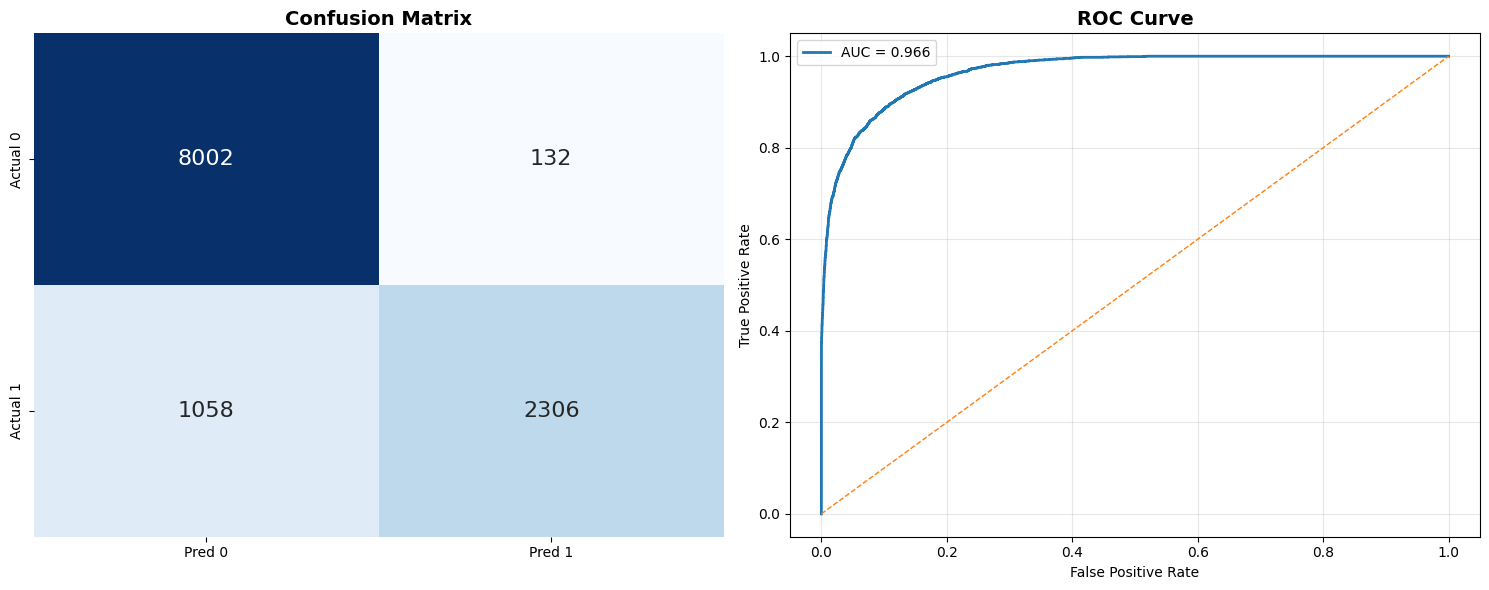

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, roc_curve
)

def report_statistical_outcomes(y_true, y_pred, y_probs=None, figsize=(15, 6)):
    metrics = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1 Score": f1_score(y_true, y_pred, zero_division=0),
    }

    if y_probs is not None:
        roc_score = roc_auc_score(y_true, y_probs)
        fpr, tpr, _ = roc_curve(y_true, y_probs)
    else:
        roc_score = roc_auc_score(y_true, y_pred)
        fpr, tpr, _ = roc_curve(y_true, y_pred)

    metrics["ROC AUC"] = roc_score

    print("## Model Performance Report ##")
    print("-" * 30)
    df_metrics = pd.DataFrame(metrics, index=[0]).T
    df_metrics.columns = ['Score']
    print(df_metrics)
    print("-" * 30)

    fig, axes = plt.subplots(1, 2, figsize=figsize)

    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', cbar=False,
        xticklabels=['Pred 0', 'Pred 1'],
        yticklabels=['Actual 0', 'Actual 1'],
        ax=axes[0], annot_kws={"size": 16}
    )
    axes[0].set_title("Confusion Matrix", fontsize=14, fontweight='bold')

    axes[1].plot(fpr, tpr, lw=2, label=f'AUC = {roc_score:.3f}')
    axes[1].plot([0, 1], [0, 1], linestyle='--', lw=1)
    axes[1].set_xlabel('False Positive Rate')
    axes[1].set_ylabel('True Positive Rate')
    axes[1].set_title('ROC Curve', fontsize=14, fontweight='bold')
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


report_statistical_outcomes(y_test, y_pred, y_probs)